In [7]:
import pandas as pd

try:
    # Load excel file menggunakan engine openpyxl secara eksplisit
    xls = pd.ExcelFile('Online Retail.xlsx', engine='openpyxl')
    print("Sheet names:", xls.sheet_names)

    df_raw = pd.read_excel('Online Retail.xlsx', engine='openpyxl')
    print("Columns:", df_raw.columns.tolist())
    print("Shape:", df_raw.shape)
    print(df_raw.head())
except Exception as e:
    print(f"Gagal membaca file: {e}")
    print("Pastikan file 'Online Retail.xlsx' terunduh dengan lengkap dan tidak rusak.")

Sheet names: ['Online Retail']
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Shape: (541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read file Excel lokal
df_raw = pd.read_excel('Online Retail.xlsx')

# Sampling 10% baris (Requirement)
df = df_raw.sample(frac=0.10, random_state=42).reset_index(drop=True)

print(f"Total baris asli: {len(df_raw):,}")
print(f"Total baris sampel (10%): {len(df):,}")
df.head()

Total baris asli: 541,909
Total baris sampel (10%): 54,191


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
1,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
2,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
3,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
4,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


In [9]:
import pandas as pd

# Memastikan variabel 'df' tersedia di namespace
if 'df' not in locals() and 'df' not in globals():
    if 'df_raw' in locals() or 'df_raw' in globals():
        # Ambil sampel 10% jika df_raw tersedia
        df = df_raw.sample(frac=0.10, random_state=42).reset_index(drop=True)
        print("Variabel 'df' dibuat ulang secara otomatis dari sampel df_raw.")
    else:
        raise NameError("Variabel 'df' dan 'df_raw' belum didefinisikan. Silakan jalankan sel di atasnya terlebih dahulu.")

# Bersihkan data dan definisikan df_clean serta kolom Revenue
df_clean = df.dropna(subset=['CustomerID']).copy()
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(f"Data berhasil dibersihkan. Jumlah baris df_clean: {len(df_clean):,}")

Variabel 'df' dibuat ulang secara otomatis dari sampel df_raw.
Data berhasil dibersihkan. Jumlah baris df_clean: 39,635


In [10]:
# Hitung Total Revenue per Negara (Top 10)
top_10_countries = df_clean.groupby('Country')['Revenue'].sum().nlargest(10).reset_index()

/tmp/ipykernel_1021/2379781542.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


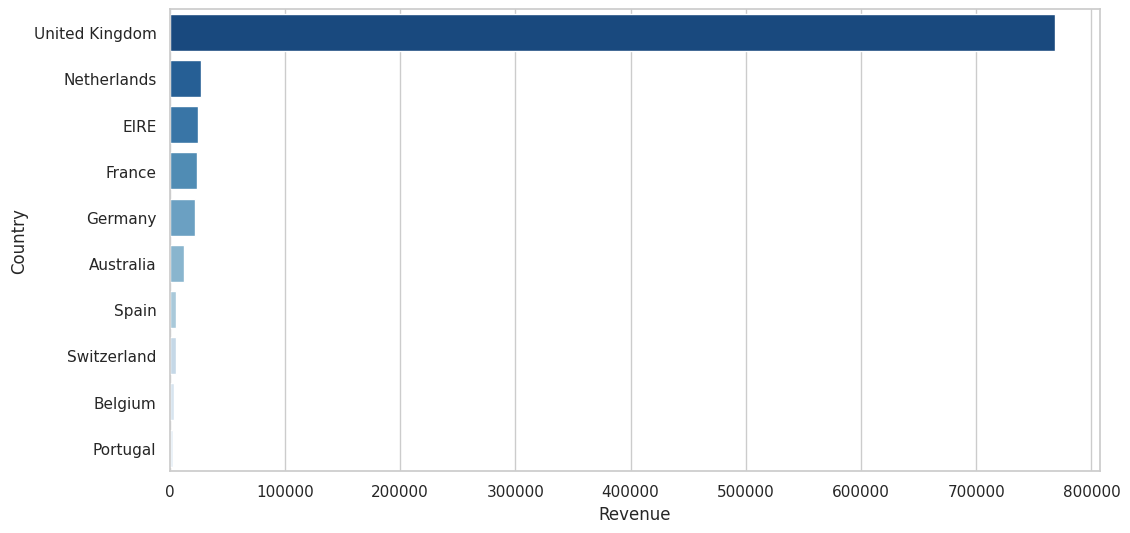

In [11]:
# Visualisasi dengan Seaborn
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_10_countries,
    x='Revenue',
    y='Country',
    palette='Blues_r'
)

Text(0, 0.5, 'Country')

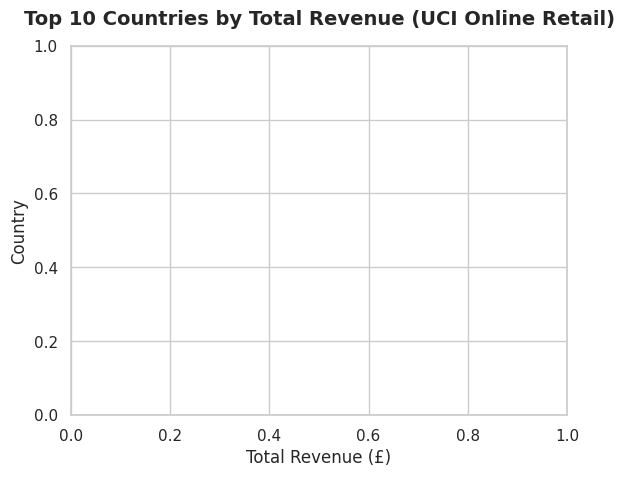

In [12]:
# Label dan Judul
plt.title('Top 10 Countries by Total Revenue (UCI Online Retail)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total Revenue (£)', fontsize=12)
plt.ylabel('Country', fontsize=12)

In [13]:
# Menambahkan angka pada setiap bar
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'£{width:,.2f}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=10)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [14]:
# Simpan grafik sebagai file PNG
plt.savefig('top_10_countries_revenue.png', dpi=300, bbox_inches='tight')
print("File top_10_countries_revenue.png berhasil disimpan!")

plt.show()

File top_10_countries_revenue.png berhasil disimpan!


<Figure size 640x480 with 0 Axes>